In [1]:
# Setup
import numpy as np # Core numerical and array operations
import pandas as pd # Data table and analysis operations
import matplotlib.pyplot as plt # Plotting; syntax and appearance similar to Matlab
import pathlib # file handling robust to switching between Mac, PC, and Linux platforms
import geopandas as gpd # GIS functionality added to pandas. We will use lightly here to make a map.

In [2]:
cwd = pathlib.Path().cwd() # Current working directory
cwd

PosixPath('/Users/symptom_of_indigo/Documents/The858')

In [3]:
inputdir = cwd / 'inputdata' # pathlib abstracts the Mac vs. PC syntax difference using '/' not as a string
# but an operator here (see e.g. https://en.wikipedia.org/wiki/Operator_overloading)
inputdir

PosixPath('/Users/symptom_of_indigo/Documents/The858/inputdata')

In [4]:
datafile = inputdir / 'CARB-UCB-CA_VMT_Estimates_DataVintage_Oct2025_PRELIMINARY_FOR_STUDENT_USE.csv'
# hard-coded input file name to match the file you'll find on Canvas.

# Read the data into a pandas Dataframe
data = pd.read_csv(datafile)
data.head()

,1,GEOID,RetDens_bg_z,DensBusStops_one_z,NetLoadDens_GF18_two_z,JobsWi45_transit_to_car_ratio,JobsWithin45_Car_z,StreetDens_GF18_two_z,cbsa_IE,cbsa_LA_OC,VMT_state,VMT_state_trunc,VMT_diff_state,VMT_CBSA,VMT_CBSA_trunc,VMT_diff_CBSA
0,2,60259400003,0.130,0.362,3.634,-0.190,0.735,0.3702,0.0,0.0,5.040,5.040,6.370,5.040,5.040,3.273
1,3,60250108002,0.133,0.362,3.500,0.000,0.698,0.4617,0.0,0.0,5.155,5.155,6.486,5.155,5.155,3.388
2,4,60250108001,0.133,0.362,3.511,0.000,0.692,0.4865,0.0,0.0,5.185,5.185,6.515,5.185,5.185,3.418
3,5,60250111003,0.133,0.362,3.513,0.000,0.681,0.4965,0.0,0.0,5.185,5.185,6.516,5.185,5.185,3.418
4,6,60730100132,-0.025,0.042,-2.598,-0.764,-0.048,-0.2850,0.0,0.0,-3.677,-3.677,-2.346,-3.677,-3.677,-2.384


In [5]:
data['GEOID'] = data['GEOID'].map(str).str.zfill(12)
data.head()

,1,GEOID,RetDens_bg_z,DensBusStops_one_z,NetLoadDens_GF18_two_z,JobsWi45_transit_to_car_ratio,JobsWithin45_Car_z,StreetDens_GF18_two_z,cbsa_IE,cbsa_LA_OC,VMT_state,VMT_state_trunc,VMT_diff_state,VMT_CBSA,VMT_CBSA_trunc,VMT_diff_CBSA
0,2,060259400003,0.130,0.362,3.634,-0.190,0.735,0.3702,0.0,0.0,5.040,5.040,6.370,5.040,5.040,3.273
1,3,060250108002,0.133,0.362,3.500,0.000,0.698,0.4617,0.0,0.0,5.155,5.155,6.486,5.155,5.155,3.388
2,4,060250108001,0.133,0.362,3.511,0.000,0.692,0.4865,0.0,0.0,5.185,5.185,6.515,5.185,5.185,3.418
3,5,060250111003,0.133,0.362,3.513,0.000,0.681,0.4965,0.0,0.0,5.185,5.185,6.516,5.185,5.185,3.418
4,6,060730100132,-0.025,0.042,-2.598,-0.764,-0.048,-0.2850,0.0,0.0,-3.677,-3.677,-2.346,-3.677,-3.677,-2.384


In [6]:
data_cleaned = data.set_index('GEOID')[['VMT_diff_state']]
# set index and keep only a list of columns with one member (hence the double brackets)
data_cleaned.head()

,VMT_diff_state
GEOID,
060259400003,6.370
060250108002,6.486
060250108001,6.515
060250111003,6.516
060730100132,-2.346


In [7]:
data_cleaned.describe()

,VMT_diff_state
count,23190.000000
mean,-0.256459
std,4.770563
min,-14.135000
25%,-2.704750
50%,0.303000
75%,2.936000
max,10.676000


In [8]:
VMT_state = 716 / 39.5 # million VMT/day / million people = #VMT/person/day
VMT_state

18.126582278481013

In [9]:
vmt = data_cleaned + VMT_state
vmt = vmt.rename({'VMT_diff_state': 'VMTpc'}, axis=1) # rename, using VMTpc as a shorthand for VMT per capita [per day]
vmt.describe()

,VMTpc
count,23190.000000
mean,17.870123
std,4.770563
min,3.991582
25%,15.421832
50%,18.429582
75%,21.062582
max,28.802582


In [10]:
ca_cbg_shapefile_path = inputdir / 'cb_2019_06_bg_500k' / 'cb_2019_06_bg_500k.shp'
gdf = gpd.read_file(ca_cbg_shapefile_path) # Basic geopandas read; it will figure out it is a shapefile format.
gdf.head() # dataframe functions are inherited by geodataframes, in addition to geodataframe specific functions. 

,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,geometry
0,06,037,800408,1,1500000US060378004081,060378004081,1,BG,2792751,1500447,"POLYGON ((-118.78754 34.02718, -118.78607 34.0..."
1,06,041,124200,4,1500000US060411242004,060411242004,4,BG,2259455,973726,"POLYGON ((-122.48698 37.89918, -122.48416 37.9..."
2,06,059,062619,4,1500000US060590626194,060590626194,4,BG,369794,343273,"POLYGON ((-117.77753 33.53639, -117.77558 33.5..."
3,06,051,000101,1,1500000US060510001011,060510001011,1,BG,2978150540,1148631,"POLYGON ((-118.94597 37.77522, -118.94348 37.7..."
4,06,093,000200,1,1500000US060930002001,060930002001,1,BG,1300052761,72751421,"POLYGON ((-122.25174 41.75805, -122.24754 41.7..."


<Axes: >

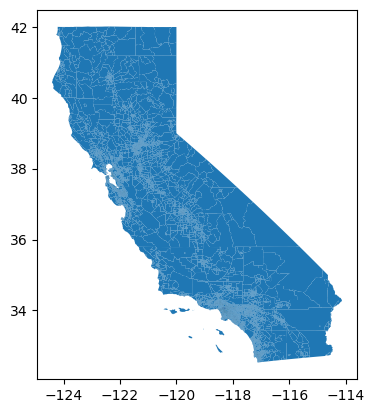

In [11]:
gdf.plot()

In [12]:
gdf['ALAND'].sum() / 1e6 # convert from square meters to square kilometers

np.float64(403660.088482)

In [13]:
sf_shape = gdf[gdf['COUNTYFP'] == '075']
# This is a basic dataframe filter. Inside the brackets we are creating a logical series and then selecting the
# rows where the logical is True.
# Compare lengths:
len(sf_shape)

580

In [14]:
len(gdf)

23196

<Axes: >

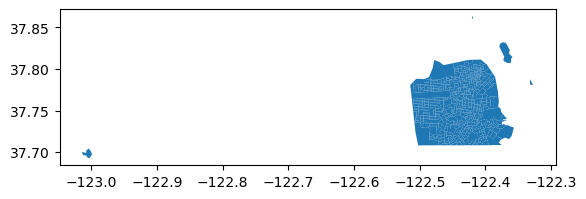

In [15]:
sf_shape.plot()

In [16]:
sf_shape['ALAND'].sum() / 1e6 / 1.61**2 # convert from square meters to square miles, since we know SF is about 49 sq mi

np.float64(46.86460514640638)

In [17]:
merged = sf_shape.merge(vmt, left_on='GEOID', right_index=True, how='inner')
# This means merge keying on the GEOID column of the left variable, the index of the right variable, using merge
# method inner.
# First check the length.
len(merged)

580

In [18]:
merged.head()

,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER,geometry,VMTpc
7,06,075,010800,1,1500000US060750108001,060750108001,1,BG,92109,0,"POLYGON ((-122.41722 37.79847, -122.41228 37.7...",3.991582
16,06,075,061100,2,1500000US060750611002,060750611002,2,BG,54921,0,"POLYGON ((-122.40825 37.79582, -122.40514 37.7...",3.991582
18,06,075,012800,4,1500000US060750128004,060750128004,4,BG,73689,0,"POLYGON ((-122.44747 37.79939, -122.44118 37.8...",3.991582
29,06,075,061400,3,1500000US060750614003,060750614003,3,BG,137098,0,"POLYGON ((-122.40369 37.75701, -122.39797 37.7...",3.991582
57,06,075,015600,2,1500000US060750156002,060750156002,2,BG,83091,0,"POLYGON ((-122.4585 37.77619, -122.45686 37.77...",3.991582


In [19]:
sf_vmt = merged.set_index('GEOID')[['VMTpc', 'geometry']]
sf_vmt.head()

,VMTpc,geometry
GEOID,,
060750108001,3.991582,"POLYGON ((-122.41722 37.79847, -122.41228 37.7..."
060750611002,3.991582,"POLYGON ((-122.40825 37.79582, -122.40514 37.7..."
060750128004,3.991582,"POLYGON ((-122.44747 37.79939, -122.44118 37.8..."
060750614003,3.991582,"POLYGON ((-122.40369 37.75701, -122.39797 37.7..."
060750156002,3.991582,"POLYGON ((-122.4585 37.77619, -122.45686 37.77..."


In [55]:
sf_vmt.explore(column='VMTpc', tiles='CartoDB positron', cmap='jet',
              vmin=4, vmax=15)
# Plot the column VMTpc, using the background defined by 'CartoDB positron', and the colormap 'jet'.

In [21]:
ca_pop_data_file = inputdir / 'ACSDT5Y2019.B01003-Data.csv'
ca_pop_data = pd.read_csv(ca_pop_data_file)
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4
0,Geography,Geographic Area Name,Estimate!!Total,Margin of Error!!Total,NaN
1,1500000US060014001001,"Block Group 1, Census Tract 4001, Alameda Coun...",3120,208,NaN
2,1500000US060014002001,"Block Group 1, Census Tract 4002, Alameda Coun...",990,138,NaN
3,1500000US060014002002,"Block Group 2, Census Tract 4002, Alameda Coun...",1017,123,NaN
4,1500000US060014003001,"Block Group 1, Census Tract 4003, Alameda Coun...",1134,238,NaN


In [22]:

ca_pop_data = pd.read_csv(ca_pop_data_file, skiprows=[1])
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4
0,1500000US060014001001,"Block Group 1, Census Tract 4001, Alameda Coun...",3120,208,NaN
1,1500000US060014002001,"Block Group 1, Census Tract 4002, Alameda Coun...",990,138,NaN
2,1500000US060014002002,"Block Group 2, Census Tract 4002, Alameda Coun...",1017,123,NaN
3,1500000US060014003001,"Block Group 1, Census Tract 4003, Alameda Coun...",1134,238,NaN
4,1500000US060014003002,"Block Group 2, Census Tract 4003, Alameda Coun...",1237,263,NaN


In [23]:
len("1500000US")

9

In [24]:
ca_pop_data['GEOID'] = ca_pop_data['GEO_ID'].map(lambda x: x[9:]) # for each element, which is a string,
# slice off the first 9 characters.
ca_pop_data.head()

,GEO_ID,NAME,B01003_001E,B01003_001M,Unnamed: 4,GEOID
0,1500000US060014001001,"Block Group 1, Census Tract 4001, Alameda Coun...",3120,208,NaN,060014001001
1,1500000US060014002001,"Block Group 1, Census Tract 4002, Alameda Coun...",990,138,NaN,060014002001
2,1500000US060014002002,"Block Group 2, Census Tract 4002, Alameda Coun...",1017,123,NaN,060014002002
3,1500000US060014003001,"Block Group 1, Census Tract 4003, Alameda Coun...",1134,238,NaN,060014003001
4,1500000US060014003002,"Block Group 2, Census Tract 4003, Alameda Coun...",1237,263,NaN,060014003002


In [25]:
ca_pop_data['GEOID'].map(len).max()
# Apply the [built-in python] "len" function to each element, then take the max of the resulting sseries.

12

In [26]:
ca_pop_data['GEOID'].map(len).min()

12

In [27]:
pop = ca_pop_data.set_index('GEOID')[['B01003_001E']].rename({'B01003_001E': 'Population'}, axis=1)
pop.head()

,Population
GEOID,
060014001001,3120
060014002001,990
060014002002,1017
060014003001,1134
060014003002,1237


In [28]:

pop.sum()

Population    39283497
dtype: int64

In [29]:
def read_census_table(table_name, filename, variable_name,
                      skiprows=[1], inputdir=inputdir, geo_in_name='GEO_ID', geo_out_name='GEOID', trim_length=9,
                      column_suffix='_001E'):
    # Function header defines the function name and its arguments.
    # Ideally, you would document the expected data type, units, or other conventions for each of these arguments.
    # Notice the first set of arguments are left open while the others have defaults set. This way we can
    # have it work as above but if we had to customize one of these options later they wouldn't be hard-coded.

    # Read data
    data = pd.read_csv(inputdir / filename, skiprows=skiprows)

    # Trim leading FIPS code strings.
    data[geo_out_name] = data[geo_in_name].map(lambda x: x[trim_length:])

    # Set index, rename column to something more readable, and drop other columns.
    column_name = table_name + column_suffix # Using '+' for a string concatenates.
    data_out = data.set_index(geo_out_name)[[column_name]].rename({column_name: variable_name}, axis=1)
    
    return data_out

In [30]:
read_census_table('B01003', 'ACSDT5Y2019.B01003-Data.csv', 'Population').sum()

Population    39283497
dtype: int64

In [31]:
housing_units = read_census_table('B25001', 'ACSDT5Y2019.B25001-Data.csv', 'Housing Units')
housing_units.head()

,Housing Units
GEOID,
060014001001,1354
060014002001,435
060014002002,425
060014003001,449
060014003002,758


In [32]:
housing_units.sum()

Housing Units    14175976
dtype: int64

In [33]:
pop.sum().values / housing_units.sum().values

array([2.77113174])

In [34]:
len(pop)

23212

In [35]:
len(housing_units)

23212

In [36]:

len(vmt)

23190

In [37]:
vmt_merged = vmt.merge(pop, left_index=True, right_index=True, how='inner')
vmt_merged = vmt_merged.merge(housing_units, left_index=True, right_index=True, how='inner')
vmt_merged.head()

,VMTpc,Population,Housing Units
GEOID,,,
060259400003,24.496582,382,485
060250108002,24.612582,809,332
060250108001,24.641582,319,158
060250111003,24.642582,2010,669
060730100132,15.780582,3148,879


In [38]:
len(vmt_merged)

23190

In [39]:
statewide_mean_vmt_calc = (vmt_merged['VMTpc'] * vmt_merged['Population']).sum() / vmt_merged['Population'].sum()
statewide_mean_vmt_calc

np.float64(18.135571996504336)

In [40]:
statewide_mean_vmt_calc - VMT_state

np.float64(0.008989718023322268)

In [41]:
(vmt_merged['VMTpc'] * vmt_merged['Housing Units']).sum() / vmt_merged['Housing Units'].sum()

np.float64(18.10789428683938)

Text(0, 0.5, 'Million People')

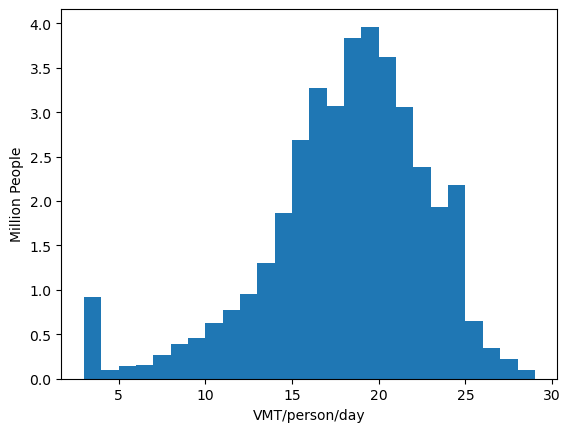

In [42]:
plt.hist(vmt_merged['VMTpc'], weights=vmt_merged['Population'] / 1e6, bins=np.arange(3, 30))
# Set bins to be 1 VMT from 3 to 30, use millions of people for plotting convenience.
plt.xlabel('VMT/person/day')
plt.ylabel('Million People')

Text(0.5, 0, 'VMT/person/day')

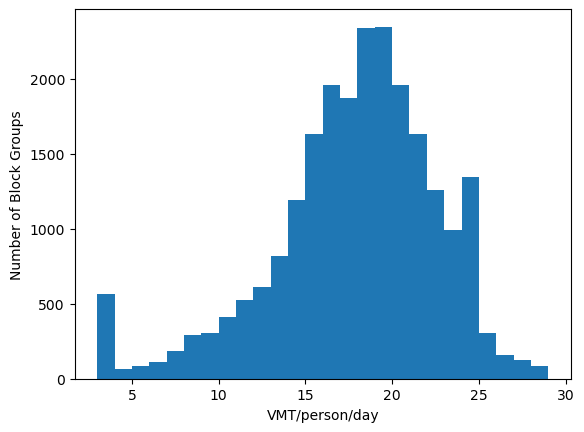

In [43]:
plt.hist(vmt_merged['VMTpc'], bins=np.arange(3, 30))
plt.ylabel('Number of Block Groups')
plt.xlabel('VMT/person/day')

In [44]:
vmt_merged = vmt_merged.merge(gdf[['GEOID', 'ALAND']], left_index=True, right_on='GEOID', how='inner')
vmt_merged = vmt_merged.set_index('GEOID')
vmt_merged.head()

,VMTpc,Population,Housing Units,ALAND
GEOID,,,,
060259400003,24.496582,382,485,12261531
060250108002,24.612582,809,332,59331725
060250108001,24.641582,319,158,230656792
060250111003,24.642582,2010,669,1267850
060730100132,15.780582,3148,879,404606


In [45]:

len(vmt_merged)

23190

In [46]:
vmt_merged['Population Density'] = vmt_merged['Population'] / vmt_merged['ALAND'] * 1e6 * 1.61**2
# people/m^2 * m^2/km^2 * km^2/mi^2 = people/mi^2.
vmt_merged.describe()

,VMTpc,Population,Housing Units,ALAND,Population Density
count,23190.000000,23190.000000,23190.000000,2.319000e+04,23190.000000
mean,17.870123,1693.984347,611.296938,1.740664e+07,9417.824593
std,4.770563,1116.008225,376.984896,2.047075e+08,10211.857747
min,3.991582,0.000000,0.000000,1.540600e+04,0.000000
25%,15.421832,1031.000000,380.000000,2.989952e+05,3243.531301
50%,18.429582,1475.000000,530.000000,5.462205e+05,7014.690663
75%,21.062582,2076.000000,747.000000,1.296322e+06,12071.608896
max,28.802582,38754.000000,7624.000000,1.599336e+10,188611.196936


Text(0.5, 0, 'Log$_{10}$ Population Density (people per sq mi)')

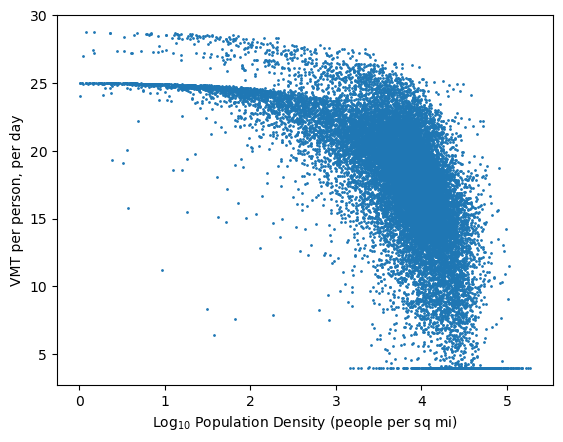

In [47]:
# Scatterplot
# First filter to rows with > 0 pop density. We'll use > 1 to avoid small floating point issues.
vmt_subset = vmt_merged[vmt_merged['Population Density'] > 1]

plt.scatter(np.log10(vmt_subset['Population Density']), vmt_subset['VMTpc'], s=1)
# scatter(x, y); we set optional argument s=1 to keep the markers small.
plt.ylabel('VMT per person, per day')
plt.xlabel('Log$_{10}$ Population Density (people per sq mi)')

In [48]:
np.corrcoef(np.log10(vmt_subset['Population Density']), vmt_subset['VMTpc'])

array([[ 1.        , -0.63766904],
       [-0.63766904,  1.        ]])

In [49]:
len(sf_vmt)

580

In [50]:
sf_vmt = sf_vmt.merge(pop, left_index=True, right_index=True, how='inner')
sf_vmt = sf_vmt.merge(housing_units,left_index=True, right_index=True, how='inner') 
len(sf_vmt)

580

In [51]:
sf_vmt.head()

,VMTpc,geometry,Population,Housing Units
GEOID,,,,
060750108001,3.991582,"POLYGON ((-122.41722 37.79847, -122.41228 37.7...",1680,798
060750611002,3.991582,"POLYGON ((-122.40825 37.79582, -122.40514 37.7...",2791,1294
060750128004,3.991582,"POLYGON ((-122.44747 37.79939, -122.44118 37.8...",506,586
060750614003,3.991582,"POLYGON ((-122.40369 37.75701, -122.39797 37.7...",1234,628
060750156002,3.991582,"POLYGON ((-122.4585 37.77619, -122.45686 37.77...",1848,697


In [52]:
sf_popmean_vmt = (sf_vmt['VMTpc'] * sf_vmt['Population']).sum() / sf_vmt['Population'].sum()
sf_popmean_vmt

np.float64(5.868372933150193)

In [53]:
sf_popmean_vmt - statewide_mean_vmt_calc

np.float64(-12.267199063354143)

In [54]:
deciles = np.arange(0, 1.1, 0.1)
sf_vmt_deciles = np.quantile(sf_vmt['VMTpc'], deciles, weights=sf_vmt['Population'],
                            method='inverted_cdf')

# To make it easier to look at, let's make a dictionary using "Dictionary Comprehension" (e.g. https://www.geeksforgeeks.org/python/python-dictionary-comprehension/).
sf_vmt_deciles = {round(deciles[x], 1): round(sf_vmt_deciles[x], 1) for x in range(len(deciles))}
sf_vmt_deciles

{np.float64(0.0): np.float64(4.0),
 np.float64(0.1): np.float64(4.0),
 np.float64(0.2): np.float64(4.0),
 np.float64(0.3): np.float64(4.0),
 np.float64(0.4): np.float64(4.0),
 np.float64(0.5): np.float64(4.0),
 np.float64(0.6): np.float64(6.0),
 np.float64(0.7): np.float64(7.3),
 np.float64(0.8): np.float64(8.2),
 np.float64(0.9): np.float64(9.1),
 np.float64(1.0): np.float64(17.8)}

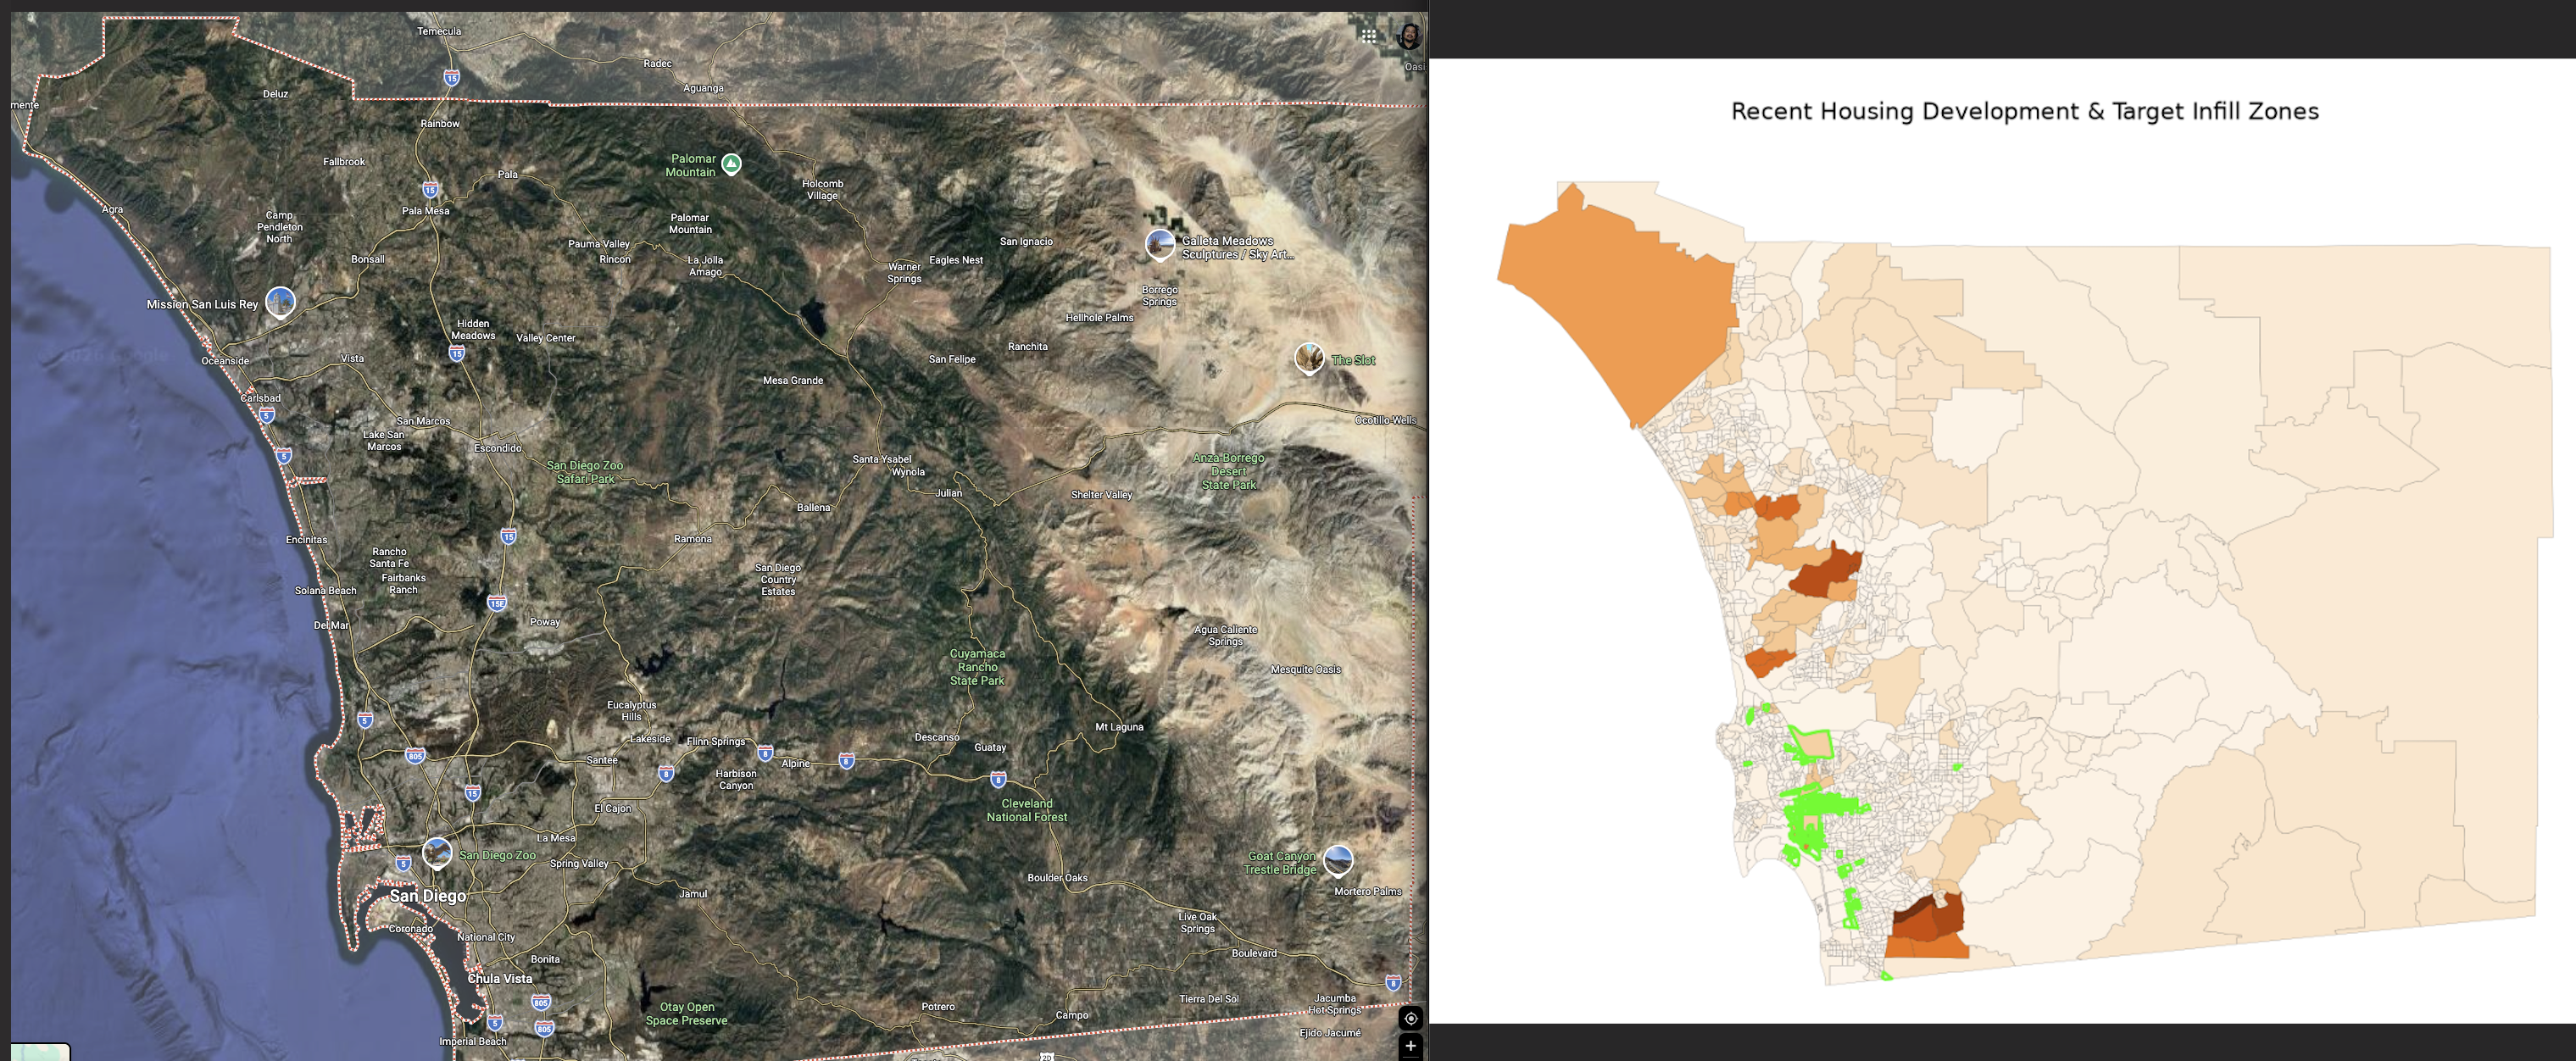

In [7]:
from IPython.display import Image, display

display(Image(filename='screenshots/Screenshot 2026-10-12 at 11.13.35 AM.png', width=2000))


Recall our fun fact - between 2022-2025 than any other county in the state, except for Riverside. 36,000 housing units were added during that period, for an annual average of 12,000 units.

https://chpd.ucsd.edu/san-diegos-population-is-growing-is-housing-construction-keeping-up-kind-of/

We know from Week 5 (Last Weeks Class)

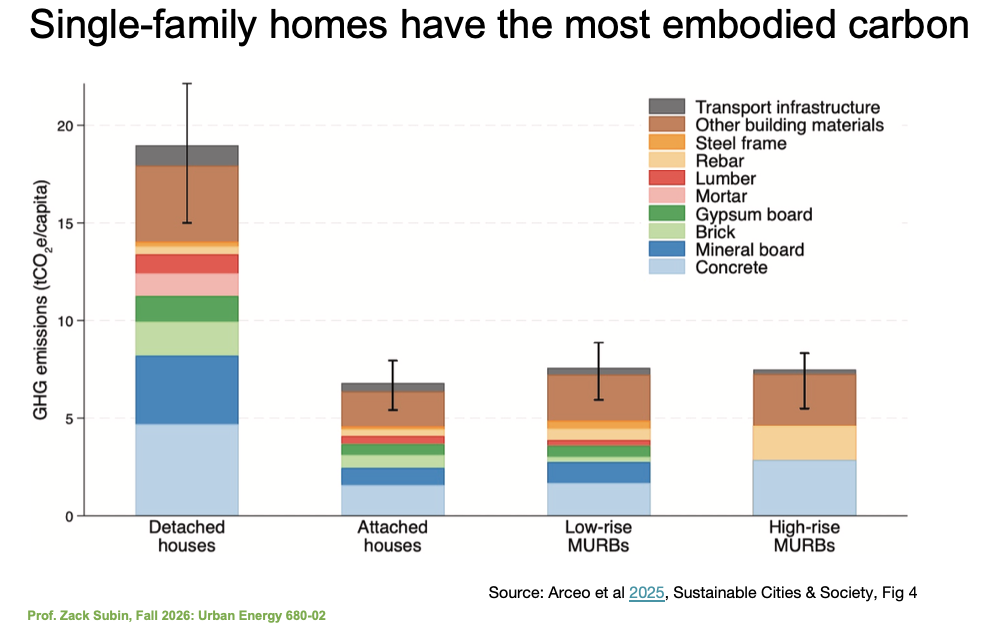

In [8]:
from IPython.display import Image, display

display(Image(filename='screenshots/Screenshot 2026-10-12 at 11.41.06 AM.png', width=2000))


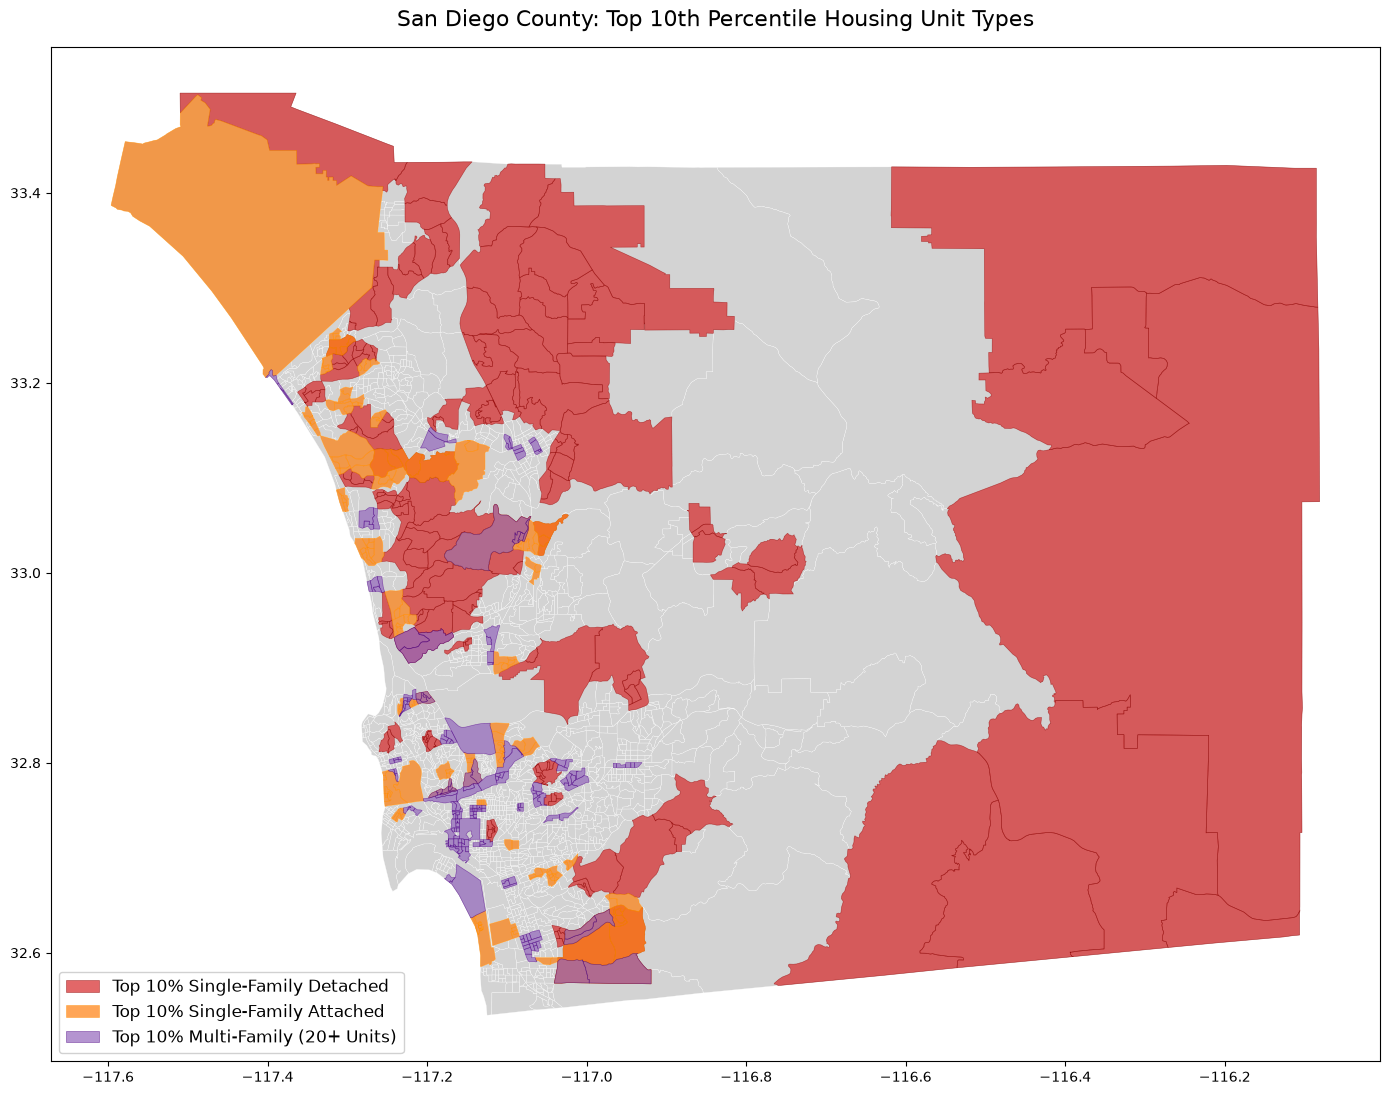

In [9]:
from IPython.display import Image, display

display(Image(filename='screenshots/download.png', width=2000))


Sources
https://www.sandiego.gov/planning/work/general-plan/housing-element


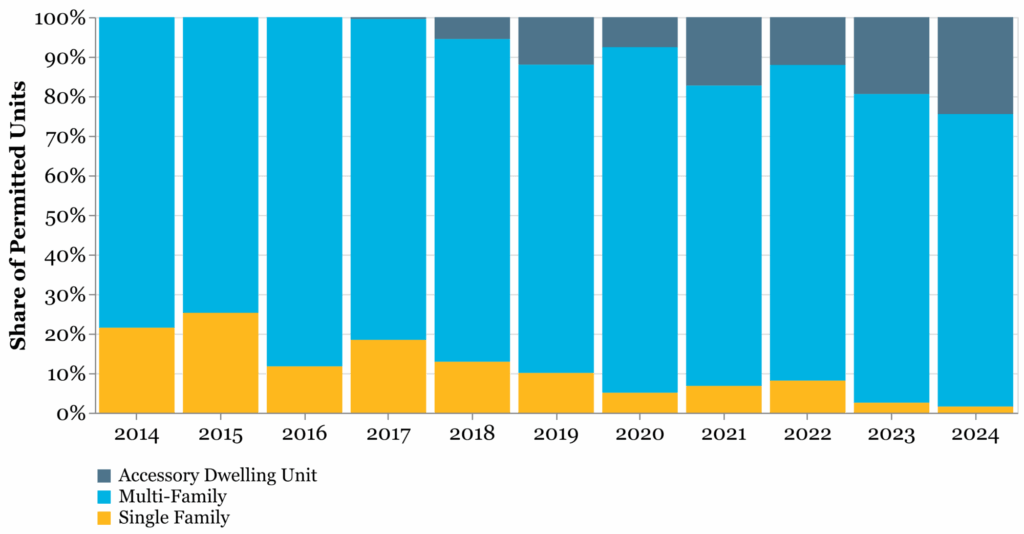

In [ ]:
#Sources Figure 4: Permitted Unit Type as a Percent of Total Units, City of San Diego 2014-2024
#https://www.sandiego.gov/planning/work/general-plan/housing-element

from IPython.display import Image, display

display(Image(filename='screenshots/SDunit_type_share10.25-1024x534.png', width=600))


https://ternercenter.berkeley.edu/research-and-policy/san-diego-adu-bonus-program/

"The ADU Bonus Program creates new opportunities for first-time builders." (Source: San Diego’s Success in Spurring Missing Middle Housing: The Accessory Dwelling Unit Bonus Program byMuhammad Alameldin, Quinn Underriner)

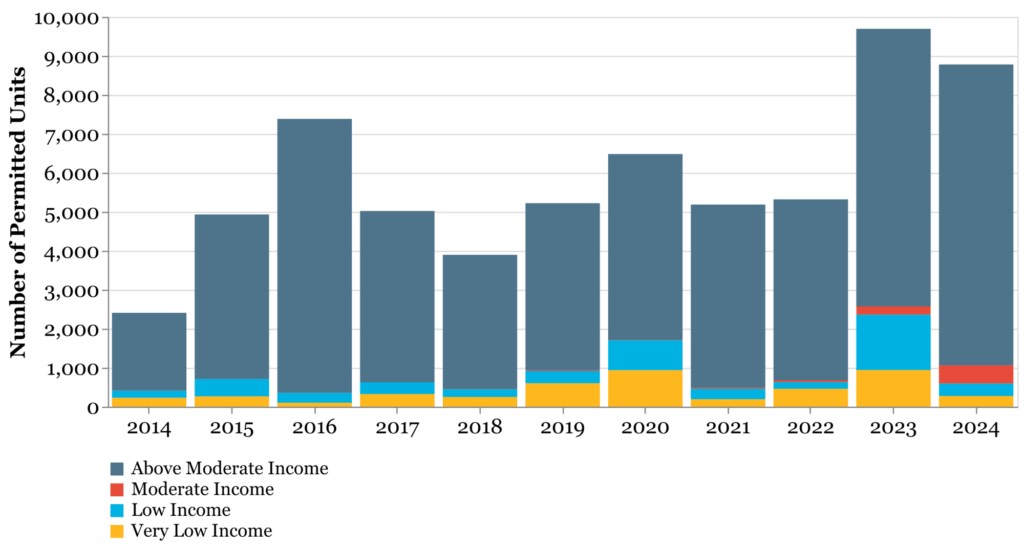

In [18]:
#Sources Figure 3: Total Permitted Units by Income Group, City of San Diego 2014-2024
#https://ternercenter.berkeley.edu/blog/steps-local-governments-can-take-to-unlock-more-housing-lessons-from-san-diego/
from IPython.display import Image, display

display(Image(filename='screenshots/SDincome_permits10.25-1024x547.png', width=600))


Key Policy Implications
1. Land Use and Zoning Alignment
Policies must focus on eliminating single-family zoning mandates, reducing parking minimums, and implementing programmatic CEQA tiering or administrative approvals in central transit priority areas.

3. Equity & Reducing Emobdied Carbon
Promoting development in existing urban infill networks avoids expanding high-risk distribution lines and reduces total system costs.

Gaps & Rooms for Further Research
1. Integrated Climate Risk vs. Decarbonization Trade-off Modeling
https://www.ternerlabs.org/blog/simulatorintro findings of policy modeling

2. Socioeconomic Equity, Displacement, and Insurance Burden
Research should analyze whether restrictive zoning and high land acquisition costs in the urban core are driving lower- and middle-income households to the peripheral foothills, where housing is cheaper upfront but burdened by volatile insurance premiums, high energy bills, and transportation costs.

--> Chris & David



Thank you,

The 858